[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/toolkit/matplotlib.ipynb)

# Matplotlib: Figures, Axes and Honest Charts

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Build charts with the object-oriented interface and multi-panel layouts.</li>
<li>Choose bins and scales so a distribution tells its true story.</li>
<li>Fix overplotting with transparency, jitter or hexbin.</li>
<li>Apply the basic rules of an honest chart.</li>
</ul>
</div>

**Prerequisites:** <a href="../pandas-grouping/">pandas: Grouping, Merging and Reshaping</a>. **Dataset:** Online Retail II and Inside Airbnb. **Time:** about 40 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

Matplotlib draws almost every chart in Python, and seaborn, pandas plotting and many others are built on top of it. It has two interfaces, and **the choice between them is the single most important thing to learn**: the quick "state-machine" style (`plt.plot(...)`), and the **object-oriented** style (`fig, ax = plt.subplots()`), where you hold the figure and axes in variables and call methods on them. Use the second. It scales from one chart to a dashboard without confusion.

We chart real data: a year-and-a-half of retail sales, and the London Airbnb listings.

In [2]:
from mlp_data import retail, load_retail
import matplotlib.dates as mdates

cleaned = retail.clean_retail(load_retail())
sales = cleaned.sales
monthly = sales.set_index("invoice_date").resample("MS").agg(revenue=("revenue", "sum"), customers=("customer_id", "nunique"))
monthly = monthly.iloc[:-1]                                   # drop the partial final month (the data ends on 9 December 2011)
monthly.head(3)

,revenue,customers
invoice_date,,
2009-12-01,"678,926.30",951
2010-01-01,"535,094.94",700
2010-02-01,"498,994.73",769


## 1. Why the object-oriented interface

The state-machine style keeps a hidden "current figure" and "current axes", and every `plt.something()` call acts on whatever is current. That is fine for one plot and a trap for two: you lose track of which chart you are editing. The object-oriented style names them:

| Concept | What it is |
|---|---|
| **Figure** (`fig`) | the whole canvas, which can hold several charts |
| **Axes** (`ax`) | one chart: the plotting area with its x and y axis, title and labels |
| **Artist** | anything drawn: a line, a bar, a text label |

A first chart, built completely from named objects:

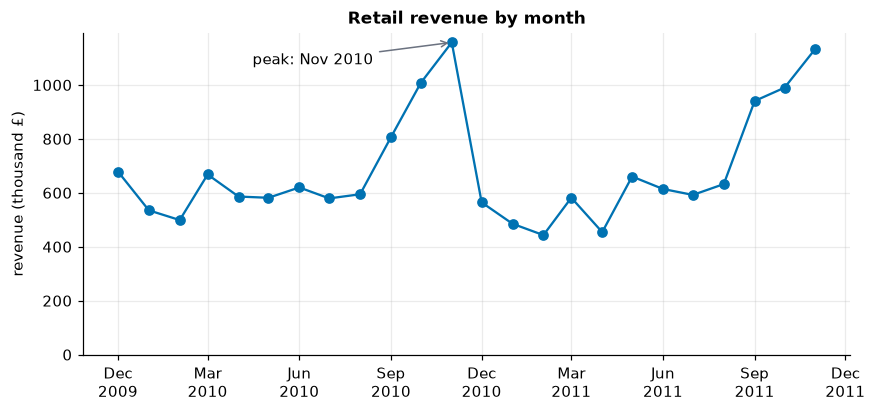

peak month: November 2010 (£1,157,765)


In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(monthly.index, monthly["revenue"] / 1e3, marker="o", color=style.BLUE)

peak = monthly["revenue"].idxmax()
ax.annotate(f"peak: {peak:%b %Y}", xy=(peak, monthly["revenue"].max() / 1e3), xytext=(peak - pd.Timedelta(days=200), monthly["revenue"].max() / 1e3 * 0.93),
            arrowprops=dict(arrowstyle="->", color=style.GREY))
ax.set(title="Retail revenue by month", ylabel="revenue (thousand £)", ylim=(0, None))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y")); ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.show()
print("peak month:", f"{peak:%B %Y}", f"(£{monthly['revenue'].max():,.0f})")

**Reading the chart.** Revenue is roughly flat for most of the year, then climbs sharply from September. In 2010 it peaks in November and drops back in December; the 2011 climb looks the same, but its fall is not yet visible because the data ends in early December. This is the seasonal build-up we meet throughout the lifecycle chapter. Setting `ylim=(0, None)` anchors the axis at zero, so the size of the swing is honest.

## 2. Several charts at once: `subplots`

Ask for a grid and you get an array of axes. `sharex=True` links the x-axes so the panels line up, and `constrained_layout` stops labels colliding.

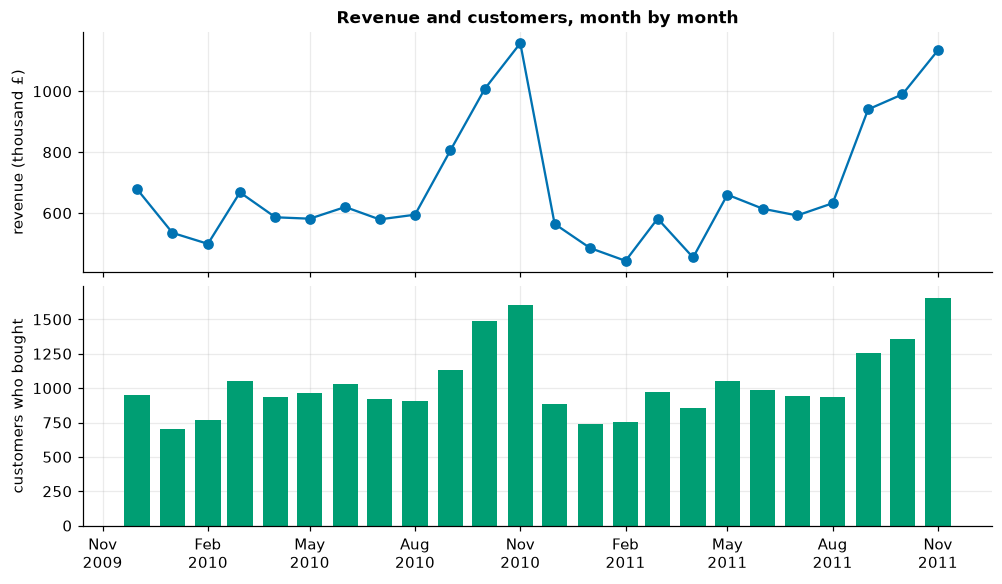

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, constrained_layout=True)
axes[0].plot(monthly.index, monthly["revenue"] / 1e3, color=style.BLUE, marker="o"); axes[0].set(ylabel="revenue (thousand £)", title="Revenue and customers, month by month")
axes[1].bar(monthly.index, monthly["customers"], width=22, color=style.GREEN); axes[1].set(ylabel="customers who bought")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y")); axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.show()

Two panels sharing a time axis let you compare *when* things happen, which is why this is usually better than one chart with two y-axes.

## 3. Twin axes: use with care

Sometimes you do want two scales on one chart. `ax.twinx()` adds a second y-axis. The danger is that two lines on two different scales can be made to look as correlated (or not) simply by choosing the axis ranges.

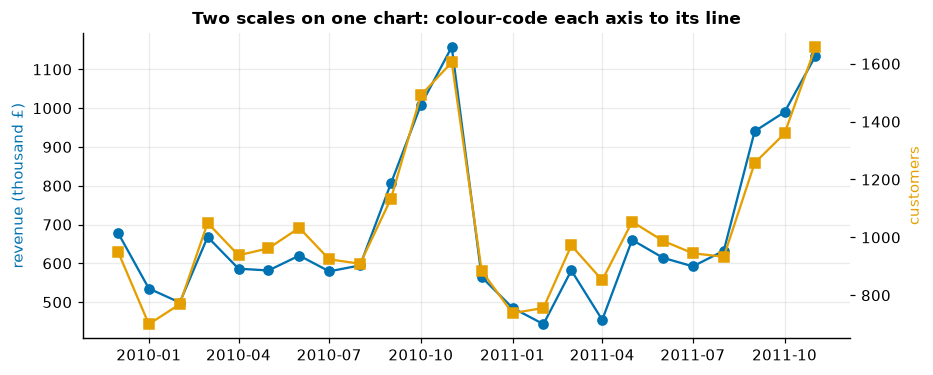

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(monthly.index, monthly["revenue"] / 1e3, color=style.BLUE, marker="o"); ax.set_ylabel("revenue (thousand £)", color=style.BLUE)
ax2 = ax.twinx()                                              # a second y-axis sharing the same x-axis
ax2.plot(monthly.index, monthly["customers"], color=style.ORANGE, marker="s"); ax2.set_ylabel("customers", color=style.ORANGE); ax2.grid(False)
ax.set_title("Two scales on one chart: colour-code each axis to its line")
plt.show()

We colour each axis label to match its line, which is the minimum courtesy to the reader. If the point is "these move together", a scatter of one against the other (or the stacked panels above) is more honest than two free-floating scales.

## 4. Distributions: the bin choice changes the story

A histogram's shape depends on its bins, and on the scale of the axis. Airbnb nightly prices are very right-skewed, so the same data tells three different stories:

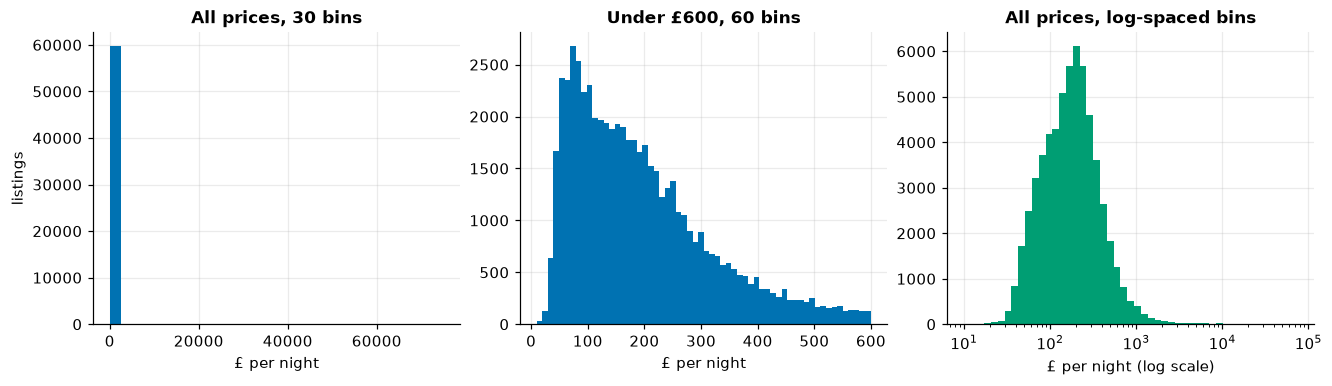

In [6]:
from mlp_data import load_airbnb
airbnb = load_airbnb()
price = pd.to_numeric(airbnb["price"].str.replace(r"[$,]", "", regex=True), errors="coerce").dropna()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), constrained_layout=True)
axes[0].hist(price, bins=30, color=style.BLUE);                       axes[0].set(title="All prices, 30 bins", xlabel="£ per night", ylabel="listings")
axes[1].hist(price[price < 600], bins=60, color=style.BLUE);          axes[1].set(title="Under £600, 60 bins", xlabel="£ per night")
axes[2].hist(price, bins=np.logspace(np.log10(price.min()), np.log10(price.max()), 50), color=style.GREEN)
axes[2].set_xscale("log");                                            axes[2].set(title="All prices, log-spaced bins", xlabel="£ per night (log scale)")
plt.show()

The first panel is a tall spike against the left wall with an invisible tail (a few extreme prices stretch the axis). Clipping to under £600 (second panel) shows the body of the distribution but *hides* that the clip happened, so say so in the title. On a **log scale** with log-spaced bins (third panel) the whole range is visible at once and the shape is a tidy hump. When data spans orders of magnitude, a log axis is usually the honest choice.

## 5. Overplotting: when there are too many points

A scatter of 90,000 points is a blob. Two cures: make points **transparent** (`alpha`), or **aggregate** the plane into hexagonal bins (`hexbin`) coloured by count.

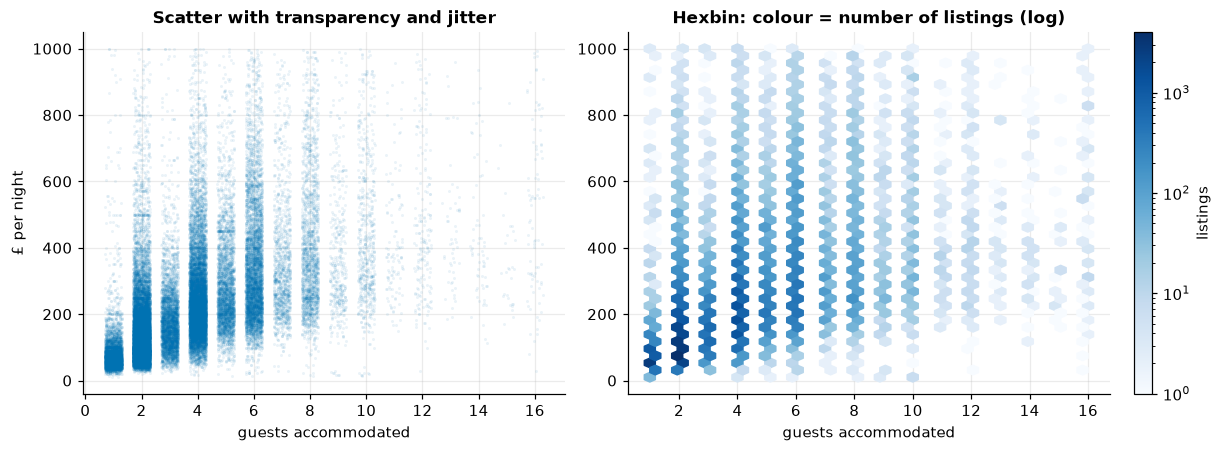

In [7]:
both = airbnb.assign(price=pd.to_numeric(airbnb["price"].str.replace(r"[$,]", "", regex=True), errors="coerce"))[["accommodates", "price"]].dropna()
both = both[both["price"] < 1000]
jitter = np.random.default_rng(0).uniform(-0.3, 0.3, len(both))               # accommodates is a whole number: jitter so points do not stack in columns

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
a.scatter(both["accommodates"] + jitter, both["price"], s=4, alpha=0.08, color=style.BLUE, linewidths=0)
a.set(title="Scatter with transparency and jitter", xlabel="guests accommodated", ylabel="£ per night")
hb = b.hexbin(both["accommodates"], both["price"], gridsize=40, cmap="Blues", mincnt=1, norm=plt.matplotlib.colors.LogNorm())
b.set(title="Hexbin: colour = number of listings (log)", xlabel="guests accommodated"); fig.colorbar(hb, ax=b, label="listings")
plt.show()

Both views show the same thing: price tends to rise with capacity but with an enormous spread at every size, and most listings cluster at small sizes and modest prices. The transparent scatter shows density as darkness (and faint horizontal lines at round prices such as £400, £450 and £500, because hosts love round numbers); the hexbin gives density a legend.

## 6. Saving figures

`fig.savefig` writes the file. Choose resolution (`dpi`) for the destination, and `bbox_inches="tight"` to trim wasted margin. Vector formats (`.svg`, `.pdf`) stay sharp at any size and suit papers; `.png` suits web pages.

In [8]:
import tempfile, os
fig, ax = plt.subplots(figsize=(6, 3)); ax.plot(monthly.index, monthly["revenue"] / 1e3, color=style.BLUE); ax.set(title="Revenue (thousand £)")
out = os.path.join(tempfile.mkdtemp(), "revenue.png")
fig.savefig(out, dpi=150, bbox_inches="tight"); plt.close(fig)                  # close figures you no longer need: they hold memory
print(f"saved {os.path.getsize(out) / 1024:.0f} KB PNG at 150 dpi")

saved 36 KB PNG at 150 dpi


## Which chart for which question

| You want to show | Use | Avoid |
|---|---|---|
| a trend over time | **line** | bars for continuous time (fine for discrete periods) |
| a comparison between categories | **bar** (zero-based baseline) | pie charts with many slices |
| the shape of one variable | **histogram** or ECDF | a bar chart of raw values |
| the relationship between two numbers | **scatter** (hexbin if dense) | a line joining unordered points |
| a part-to-whole split | stacked bar or a table | 3D anything |

**Honesty rules:** start bar charts at zero; label axes with units; do not truncate an axis to exaggerate a difference; colour for meaning (and use a colourblind-safe palette); say what was filtered.

## Check yourself

<details class="question">
<summary>1. What is the practical difference between <code>plt.plot(...)</code> and <code>ax.plot(...)</code>?</summary>

`plt.plot` acts on a hidden "current" axes, which can be a different chart from the one you expect once you have more than one. `ax.plot` acts on the specific axes object you hold, so there is no ambiguity. Hold the objects (`fig, ax = plt.subplots()`) and call methods on them.

</details>

<details class="question">
<summary>2. When is a second y-axis (<code>twinx</code>) a bad idea?</summary>

When the point is to suggest the two series are related. The visual agreement of two lines on two free scales depends entirely on the ranges you pick, so it can manufacture or hide a correlation. Prefer stacked panels sharing the x-axis, or a scatter of one series against the other.

</details>

<details class="question">
<summary>3. A scatter of 90,000 points is one solid blob. What are two fixes?</summary>

Reduce each point's opacity (`alpha`, so density shows as darkness) and/or aggregate: a `hexbin` or 2D histogram colours each cell by how many points fall in it. Jittering helps when one axis is a whole number.

</details>

## Exercises

<details class="question">
<summary>Draw a 2×2 grid showing revenue, customers, orders and revenue-per-customer by month. Share the x-axis. Which panel shows the clearest seasonal rhythm?</summary>

```python
monthly["orders"] = sales.groupby(sales["invoice_date"].dt.to_period("M").dt.to_timestamp())["invoice"].nunique().reindex(monthly.index)
monthly["revenue_per_customer"] = monthly["revenue"] / monthly["customers"]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, constrained_layout=True)
for ax, col, title in zip(axes.ravel(), ["revenue", "customers", "orders", "revenue_per_customer"], ["Revenue", "Customers", "Orders", "Revenue per customer"]):
    ax.plot(monthly.index, monthly[col], marker="o", color=style.BLUE); ax.set(title=title, ylim=(0, None))
plt.show()
```

Revenue, customers and orders all swell in the autumn. Revenue per customer is far flatter, which tells you the seasonal rise comes mainly from *more customers ordering*, not from each spending more.

</details>

<details class="question">
<summary>Here is a misleading chart: a bar chart of two bars with the y-axis starting at 4.0 instead of 0, making a small difference look huge. Redraw it honestly.</summary>

```python
values = {"Group A": 4.2, "Group B": 4.4}
fig, (bad, good) = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True)
bad.bar(values.keys(), values.values(), color=style.RED); bad.set(ylim=(4.0, 4.5), title="Misleading: axis starts at 4")
good.bar(values.keys(), values.values(), color=style.BLUE); good.set(ylim=(0, 5), title="Honest: axis starts at 0")
plt.show()
```

Both draw the same numbers, but the truncated axis makes B look about three times A. Bars encode value by *length*, so their baseline must be zero. (For lines and dots a non-zero baseline can be fine, as long as it is clearly labelled.)

</details>

## Recap

- Use the **object-oriented interface**: `fig, ax = plt.subplots(...)`, then call methods on `ax`.
- `subplots` with `sharex` and `constrained_layout` makes aligned multi-panel figures; prefer them to twin axes.
- The **bin choice and scale** change a histogram's story; use a log axis for data spanning orders of magnitude, and say what you clip.
- Fight overplotting with `alpha`, jitter or `hexbin`.
- Save with `savefig(dpi=..., bbox_inches="tight")`; close figures you are done with.
- Be honest: zero-based bars, labelled units, colour for meaning.

**Next:** *Seaborn*, statistical charts with far less code.